# DSCI 552 Homework 7
**Jun Jiang** · GitHub: `generalisjj-hub`

## 1(a)–(b)(i) Data and evaluation

We use the 22 MFCC features (not the recording identifier), the three categorical labels, and a reproducible 70/30 random split stratified by species. Each label is modeled independently, with one-versus-rest classes. Exact match is the fraction with all three labels correct. For these three categorical label positions, Hamming distance is the number of mismatched labels per observation; Hamming loss is its mean divided by three, and Hamming score is 1 − Hamming loss ([scikit-learn Hamming loss](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.hamming_loss.html)).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from threadpoolctl import threadpool_limits

seed = 552
path = Path('data/Frogs_MFCCs.csv')
if not path.exists(): path = Path('../data/Frogs_MFCCs.csv')
data = pd.read_csv(path)
X = data.iloc[:, :22].to_numpy(dtype=np.float64)
labels = ['Family', 'Genus', 'Species']
Y = data[labels].to_numpy()
train_idx, test_idx = train_test_split(np.arange(len(data)), train_size=.7,
                                       random_state=seed, stratify=Y[:,2])
Xtr, Xte, Ytr, Yte = X[train_idx], X[test_idx], Y[train_idx], Y[test_idx]
print(f'Total {len(X)}, training {len(Xtr)}, test {len(Xte)}; features {X.shape[1]}.')
print('Training class counts:')
for j, name in enumerate(labels): print(name, dict(pd.Series(Ytr[:,j]).value_counts()))

Total 7195, training 5036, test 2159; features 22.
Training class counts:
Family {'Leptodactylidae': np.int64(3093), 'Hylidae': np.int64(1516), 'Dendrobatidae': np.int64(379), 'Bufonidae': np.int64(48)}
Genus {'Adenomera': np.int64(2904), 'Hypsiboas': np.int64(1115), 'Ameerega': np.int64(379), 'Dendropsophus': np.int64(217), 'Leptodactylus': np.int64(189), 'Scinax': np.int64(104), 'Osteocephalus': np.int64(80), 'Rhinella': np.int64(48)}
Species {'AdenomeraHylaedactylus': np.int64(2434), 'HypsiboasCordobae': np.int64(785), 'AdenomeraAndre': np.int64(470), 'Ameeregatrivittata': np.int64(379), 'HypsiboasCinerascens': np.int64(330), 'HylaMinuta': np.int64(217), 'LeptodactylusFuscus': np.int64(189), 'ScinaxRuber': np.int64(104), 'OsteocephalusOophagus': np.int64(80), 'Rhinellagranulosa': np.int64(48)}


## 1(b)(ii)–(iv) SVM classifiers

For each label, we use **10-fold** stratified cross-validation to choose hyperparameters by label-level accuracy. The Gaussian SVM uses raw features, as they are already normalized in the source data; its width is determined by $\gamma=1/(2\sigma^2)$. The linear L1 SVM standardizes features inside each training fold. In the third model, inverse-frequency class weighting compensates for imbalance without generating synthetic data; the weights are recomputed using only each training fold. The same held-out test examples evaluate all three models.

In [2]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)
specifications = {
    'Gaussian': (OneVsRestClassifier(SVC(kernel='rbf')),
                 {'estimator__C': [.1, 1, 10], 'estimator__gamma': [.01, .1, 1]}),
    'Linear L1': (make_pipeline(StandardScaler(), LinearSVC(penalty='l1', dual=False,
                           max_iter=30000, random_state=seed)),
                  {'linearsvc__C': [.01, .1, 1]}),
    'Balanced Linear L1': (make_pipeline(StandardScaler(), LinearSVC(penalty='l1',
                           dual=False, class_weight='balanced', max_iter=30000,
                           random_state=seed)), {'linearsvc__C': [.01, .1, 1]})
}
predictions, tuning_rows = {}, []
with threadpool_limits(limits=1):
    for model_name, (estimator, grid) in specifications.items():
        predictions[model_name] = []
        for j, label in enumerate(labels):
            search = GridSearchCV(estimator, grid, scoring='accuracy', cv=cv, n_jobs=1)
            search.fit(Xtr, Ytr[:, j])
            predictions[model_name].append(search.predict(Xte))
            tuning_rows.append([model_name, label, str(search.best_params_), search.best_score_])
            print(f'{model_name}, {label}: CV={search.best_score_:.4f}; {search.best_params_}', flush=True)
        predictions[model_name] = np.column_stack(predictions[model_name])
tuning = pd.DataFrame(tuning_rows, columns=['Model', 'Label', 'Best parameters', 'CV accuracy'])
display(tuning.round(4))

Gaussian, Family: CV=0.9915; {'estimator__C': 10, 'estimator__gamma': 1}


Gaussian, Genus: CV=0.9901; {'estimator__C': 10, 'estimator__gamma': 1}


Gaussian, Species: CV=0.9913; {'estimator__C': 10, 'estimator__gamma': 1}


Linear L1, Family: CV=0.9382; {'linearsvc__C': 1}


Linear L1, Genus: CV=0.9519; {'linearsvc__C': 1}


Linear L1, Species: CV=0.9575; {'linearsvc__C': 1}


Balanced Linear L1, Family: CV=0.9367; {'linearsvc__C': 1}


Balanced Linear L1, Genus: CV=0.9470; {'linearsvc__C': 1}


Balanced Linear L1, Species: CV=0.9581; {'linearsvc__C': 1}


,Model,Label,Best parameters,CV accuracy
0,Gaussian,Family,"{'estimator__C': 10, 'estimator__gamma': 1}",0.9915
1,Gaussian,Genus,"{'estimator__C': 10, 'estimator__gamma': 1}",0.9901
2,Gaussian,Species,"{'estimator__C': 10, 'estimator__gamma': 1}",0.9913
3,Linear L1,Family,{'linearsvc__C': 1},0.9382
4,Linear L1,Genus,{'linearsvc__C': 1},0.9519
5,Linear L1,Species,{'linearsvc__C': 1},0.9575
6,Balanced Linear L1,Family,{'linearsvc__C': 1},0.9367
7,Balanced Linear L1,Genus,{'linearsvc__C': 1},0.9470
8,Balanced Linear L1,Species,{'linearsvc__C': 1},0.9581


In [3]:
def multilabel_metrics(truth, pred):
    errors = truth != pred
    distance = errors.sum(axis=1)
    loss = errors.mean()
    return (np.mean(distance == 0), distance.mean(), 1-loss, loss)

results = pd.DataFrame({name: multilabel_metrics(Yte, pred) for name, pred in predictions.items()},
                       index=['Exact match', 'Hamming distance', 'Hamming score', 'Hamming loss']).T
display(results.round(4))
a, b, c = (results.loc[n] for n in ['Gaussian','Linear L1','Balanced Linear L1'])
display(Markdown(f"On the held-out set, Gaussian exact match is {a['Exact match']:.4f} "
    f"and Hamming loss is {a['Hamming loss']:.4f}, versus {b['Exact match']:.4f} and "
    f"{b['Hamming loss']:.4f} for linear L1. Balancing changes L1 exact match from "
    f"{b['Exact match']:.4f} to {c['Exact match']:.4f} and Hamming loss from "
    f"{b['Hamming loss']:.4f} to {c['Hamming loss']:.4f}. Weights favor minority classes, "
    "so the aggregate score alone does not establish an improvement for every class."))

,Exact match,Hamming distance,Hamming score,Hamming loss
Gaussian,0.9861,0.0310,0.9897,0.0103
Linear L1,0.9176,0.1524,0.9492,0.0508
Balanced Linear L1,0.9092,0.1626,0.9458,0.0542


On the held-out set, Gaussian exact match is 0.9861 and Hamming loss is 0.0103, versus 0.9176 and 0.0508 for linear L1. Balancing changes L1 exact match from 0.9176 to 0.9092 and Hamming loss from 0.0508 to 0.0542. Weights favor minority classes, so the aggregate score alone does not establish an improvement for every class.

The Gaussian model has **98.61%** exact match, **6.85 percentage points** above the unweighted linear L1 model's **91.76%**. Adding class weights lowers exact match to **90.92%** and raises Hamming loss from **5.08%** to **5.42%** on this test set. However, species-level recall for the minority `OsteocephalusOophagus` rises from **19/34 (55.88%)** to **27/34 (79.41%)**; recall for `Rhinellagranulosa` stays **16/20 (80%)**. Thus weighting trades aggregate accuracy for improved recall of one minority class, not all classes.

The selected hyperparameters lie at the edge of the tested grids; they are best only within these grids, and larger values could improve performance.

## 2(a)–(c) K-means Monte Carlo

All 7,195 observations are used, without a train/test split. For each of 50 independent random initializations, we fit K-means for every k from 1 to 50; Calinski–Harabasz (CH) score selects the best k among 2–50. CH is undefined for k=1, which is fitted and recorded but cannot be chosen by this criterion. Cluster labels are assigned afterward by the majority true label separately for family, genus, and species. These label-based scores are an external, descriptive evaluation of the same data used for clustering, not held-out prediction performance. One initialization per candidate preserves the random variation across Monte Carlo runs.

In [4]:
runs = []
with threadpool_limits(limits=1):
    for run in range(50):
        best_score, best_k, best_labels, k1_inertia = -np.inf, None, None, None
        for k in range(1, 51):
            km = KMeans(n_clusters=k, n_init=1, max_iter=100, random_state=seed+run)
            group = km.fit_predict(X)
            if k == 1:
                k1_inertia = km.inertia_
                continue
            score = calinski_harabasz_score(X, group)
            if score > best_score:
                best_score, best_k, best_labels = score, k, group.copy()
        assigned = np.empty(Y.shape, dtype=object)
        for cluster in range(best_k):
            mask = best_labels == cluster
            for j in range(3):
                counts = pd.Series(Y[mask,j]).value_counts(sort=True)
                # Alphabetical order breaks any equal-count tie deterministically.
                majority = sorted(counts[counts == counts.max()].index)[0]
                assigned[mask,j] = majority
        exact, dist, hscore, loss = multilabel_metrics(Y, assigned)
        runs.append([run+1, best_k, best_score, dist, hscore, loss])
        if (run+1) % 10 == 0: print(f'Completed {run+1}/50 runs', flush=True)
runs = pd.DataFrame(runs, columns=['Run','k','CH','Hamming distance','Hamming score','Hamming loss'])
print(f"Average Hamming distance = {runs['Hamming distance'].mean():.5f}; "
      f"sample standard deviation = {runs['Hamming distance'].std(ddof=1):.5f}.")
print(f"Average Hamming score = {runs['Hamming score'].mean():.5f}; "
      f"average Hamming loss = {runs['Hamming loss'].mean():.5f}.")
print('Selected k distribution:', dict(runs.k.value_counts().sort_index()))

Completed 10/50 runs


Completed 20/50 runs


Completed 30/50 runs


Completed 40/50 runs


Completed 50/50 runs


Average Hamming distance = 0.89562; sample standard deviation = 0.00000.
Average Hamming score = 0.70146; average Hamming loss = 0.29854.
Selected k distribution: {2: np.int64(50)}


For the first run (seed 552), CH selects $k=2$. The cluster-majority triplets are:

| Cluster | Observations | Family | Genus | Species |
|---:|---:|---|---|---|
| 0 | 3,597 | Hylidae | Hypsiboas | HypsiboasCordobae |
| 1 | 3,598 | Leptodactylidae | Adenomera | AdenomeraHylaedactylus |

All 50 runs selected $k=2$ and had mean Hamming distance 0.89562 with sample standard deviation 0.00000. This is stability for these initializations, not evidence of perfect label recovery.

## 3. ISLR 12.6.2

Using the supplied dissimilarities, complete linkage first merges 1 and 2 at 0.30, then 3 and 4 at 0.45, then the two pairs at 0.80. Single linkage merges 1 and 2 at 0.30, joins 3 at 0.40, and finally joins 4 at 0.45.

(a)–(b) The dendrograms below show the merge heights and leaves. (c) Cutting the complete-linkage tree to two clusters gives **{1,2}** and **{3,4}**. (d) Cutting the single-linkage tree to two clusters gives **{1,2,3}** and **{4}**. (e) Reversing the leaves within both pairs gives leaf order **2,1,4,3**, while preserving every complete-linkage merge and height.

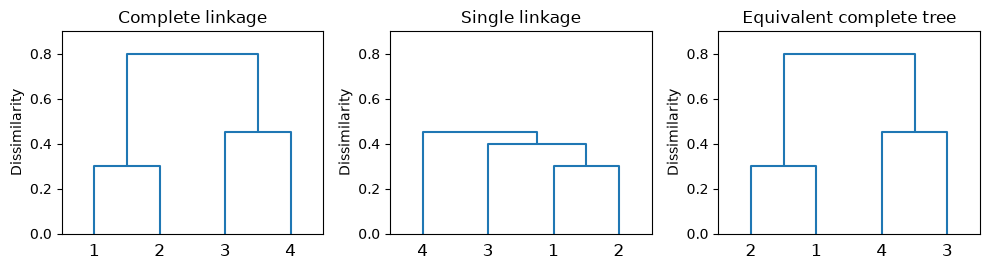

In [5]:
D = np.array([[0,.3,.4,.7],[.3,0,.5,.8],[.4,.5,0,.45],[.7,.8,.45,0]])
z_complete = linkage(squareform(D), method='complete')
z_single = linkage(squareform(D), method='single')
# Swap children within both first merges; this changes only their display order.
z_reordered = z_complete.copy()
z_reordered[:2, :2] = z_reordered[:2, :2][:, ::-1]
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, z, title in zip(axes, [z_complete, z_single, z_reordered],
                        ['Complete linkage','Single linkage','Equivalent complete tree']):
    dendrogram(z, labels=['1','2','3','4'], ax=ax, color_threshold=0)
    ax.set_title(title); ax.set_ylabel('Dissimilarity'); ax.set_ylim(0,.9)
plt.tight_layout(); plt.show()